# Estudo de Caso 8.X1 — Simulação Acoplada de Calor e Umidade em Solo: Equação de Richards com Côté & Konrad

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 8 — Transferência de Calor em Solos |
| **Nível** | Pós-Graduação |
| **Tempo estimado** | 120 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Diferenças Finitas — Esquema Implícito com Picard (acoplado termo-hídrico) |
| **Bibliografia** | Lugon Jr. et al. (2026), Cap. 8; van Genuchten (1980); Côté & Konrad (2005); Brutsaert (1975); Richards (1931); Feddes et al. (1978) |

---

## 📋 Resumo

Simulamos o comportamento acoplado de temperatura e umidade em um solo franco-arenoso ao longo de 30 dias, resolvendo simultaneamente a equação de Richards 1D (fluxo de água em meio poroso insaturado, modelo van Genuchten-Mualem) e a equação de calor com condutividade térmica dependente da umidade (modelo Côté & Konrad). A evapotranspiração é modelada com extração distribuída por raízes (modelo de Feddes) e dependência da umidade do solo. A condição de contorno superficial inclui radiação solar, radiação de onda longa com temperatura do céu (Brutsaert, 1975), convecção e precipitação. O domínio estendido a 3 m permite visualizar a atenuação exponencial da onda térmica diurna e a temperatura constante em profundidade.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Implementar** a equação de Richards 1D com o modelo hidráulico de van Genuchten-Mualem
2. **Acoplar** a equação de Richards com a equação de calor por iteração de Picard
3. **Modelar** a condutividade térmica do solo como função da umidade (Côté & Konrad)
4. **Formular** condições de contorno fisicamente realistas (radiação solar, céu, convecção, chuva)
5. **Implementar** evapotranspiração com extração distribuída por raízes (modelo de Feddes)
6. **Visualizar** o aquecimento diurno da camada superficial e o isolamento térmico do solo profundo
7. **Avaliar** a convergência do esquema acoplado e o balanço hídrico

---
## ⚙️ Seção 0: Configuração Inicial

In [56]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve
from IPython.display import display, Markdown
import time

# Constantes físicas
sigma_SB = 5.670374419e-8   # Stefan-Boltzmann [W/(m²·K⁴)]
rho_w = 1000.0              # Densidade da água [kg/m³]
c_p_w = 4180.0              # Calor específico da água [J/(kg·K)]
g = 9.81                    # Aceleração da gravidade [m/s²]

# Configuração de estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 1.26.4 | Matplotlib 3.10.1


---
## 🌡️ Seção 1: Parâmetros do Solo e Domínio

### Contexto Físico

Este estudo de caso estende o EC 8.8 (perfil térmico diurno) ao **acoplar** o transporte de calor com o fluxo de água no solo. A motivação é que a condutividade térmica do solo depende fortemente do teor de umidade: solos úmidos conduzem calor ~3× mais eficientemente que solos secos. Portanto, eventos de chuva e evapotranspiração alteram o perfil térmico do solo.

> 💡 **Observação:** A evapotranspiração foi intensificada nesta versão (ET₀ = 10 mm/dia, duração 15 h/dia) com extração distribuída por raízes até 60 cm de profundidade (modelo de Feddes). Isso amplifica a variação de umidade e, consequentemente, da condutividade térmica.

### Tabela de Parâmetros

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|------:|:-------:|
| **Propriedades hidráulicas (van Genuchten-Mualem)** | | | |
| Umidade residual | $\theta_r$ | 0,058 | m³/m³ |
| Umidade saturada | $\theta_s$ | 0,41 | m³/m³ |
| Parâmetro de entrada de ar | $\alpha$ | 7,4 | m⁻¹ |
| Parâmetro de distribuição de poros | $n$ | 1,56 | – |
| Conectividade de poros | $l$ | 0,5 | – |
| Condutividade saturada | $K_s$ | 1,0×10⁻⁵ | m/s |
| **Propriedades térmicas** | | | |
| Massa específica aparente | $\rho_b$ | 1500 | kg/m³ |
| Calor específico (sólidos) | $c_{p,s}$ | 800 | J/(kg·K) |
| Condutividade térmica seca | $k_{seco}$ | 0,3 | W/(m·K) |
| Condutividade térmica saturada | $k_{sat}$ | 1,8 | W/(m·K) |
| Parâmetro de Côté & Konrad | $\kappa$ | 1,5 | – |
| **Domínio e discretização** | | | |
| Profundidade do domínio | $H$ | 3,0 | m |
| Espaçamento espacial | $\Delta z$ | 0,05 | m |
| Passo de tempo | $\Delta t$ | 300 | s (5 min) |
| Tempo total de simulação | $t_f$ | 30 | dias |
| **Condições de contorno** | | | |
| Temperatura da base | $T_{base}$ | 15,0 | °C |
| Potencial matricial na base | $\psi_{base}$ | 0,0 | m |
| **Forçamento atmosférico** | | | |
| Radiação solar máxima | $R_s^{max}$ | 800 | W/m² |
| Absortividade solar | $\alpha_s$ | 0,85 | – |
| Emissividade da superfície | $\varepsilon_s$ | 0,95 | – |
| Coeficiente convectivo | $h_{conv}$ | 15 | W/(m²·K) |
| **Evapotranspiração (MODIFICADO)** | | | |
| ET potencial máxima | $ET_0$ | 10 | mm/dia |
| Início da ET | $t_{ini}$ | 5 | h |
| Fim da ET | $t_{fim}$ | 20 | h |
| Profundidade máxima de raízes | $z_{root}$ | 0,60 | m |
| Parâmetro de decaimento de raízes | $\beta_{root}$ | 3,0 | m⁻¹ |
| Umidade crítica (ponto de murcha) | $\theta_{crit}$ | 0,22 | m³/m³ |
| **Precipitação (MODIFICADO)** | | | |
| Eventos de chuva | dias 3, 15, 27 | – | – |
| Intensidade | 3,0 | mm/h | – |
| Duração | 6 | h | – |
| **Acoplamento** | | | |
| Máximo de iterações de Picard | $N_{iter,max}$ | 5 | – |
| Tolerância de convergência | $\epsilon_{tol}$ | 10⁻⁴ | – |

In [57]:
# ============================================================
# PARÂMETROS HIDRÁULICOS — van Genuchten-Mualem
# ============================================================

theta_r = 0.058       # Umidade residual [m³/m³]
theta_s = 0.41        # Umidade saturada [m³/m³]
alpha_vg = 7.4        # Parâmetro de entrada de ar [m⁻¹]
n_vg = 1.56           # Parâmetro de distribuição de poros [-]
m_vg = 1.0 - 1.0/n_vg  # Parâmetro derivado [-]
L_vg = 0.5            # Conectividade de poros [-]
K_s = 1.0e-5          # Condutividade hidráulica saturada [m/s]

# ============================================================
# PARÂMETROS TÉRMICOS — Côté & Konrad
# ============================================================

rho_b = 1500.0        # Massa específica aparente [kg/m³]
c_p_s = 800.0         # Calor específico dos sólidos [J/(kg·K)]
k_seco = 0.3          # Condutividade térmica seca [W/(m·K)]
k_sat = 1.8           # Condutividade térmica saturada [W/(m·K)]
kappa_CK = 1.5        # Parâmetro de Côté & Konrad [-]

# Capacidade volumétrica de calor do esqueleto sólido
C_s = rho_b * c_p_s   # [J/(m³·K)]

# ============================================================
# PARÂMETROS DE EVAPOTRANSPIRAÇÃO (MODIFICADO)
# ============================================================

ET0 = 10.0e-3 / 86400.0     # ET potencial máxima [m/s] (10 mm/dia)
t_ini_ET = 5.0               # Início da ET [h]
t_fim_ET = 20.0              # Fim da ET [h]
z_root = 0.60                # Profundidade máxima de raízes [m]
beta_root = 3.0              # Parâmetro de decaimento de raízes [m⁻¹]
theta_crit = theta_r + 0.45 * (theta_s - theta_r)  # Umidade crítica [m³/m³]

# ============================================================
# PARÂMETROS DE PRECIPITAÇÃO (MODIFICADO)
# ============================================================

eventos_chuva = [3.0, 15.0, 27.0]   # Dias de chuva (mais espaçados)
intensidade_chuva = 3.0e-3 / 3600.0  # 3 mm/h → m/s (reduzida)
duracao_chuva = 0.25                  # 6 horas = 0.25 dia

# ============================================================
# DOMÍNIO COMPUTACIONAL E DISCRETIZAÇÃO
# ============================================================

H = 3.0               # Profundidade do domínio [m]
dz = 0.05             # Espaçamento espacial [m]
dt = 300.0            # Passo de tempo [s] (5 minutos)
t_total = 30 * 24 * 3600.0  # 30 dias [s]

# Vetores de discretização
z = np.arange(0, H + dz, dz)      # Posições [m]
Nz = len(z)                        # Número de nós (61)
Nt = int(t_total / dt) + 1         # Número de passos temporais
t_sec = np.linspace(0, t_total, Nt)  # Tempos [s]
t_dias = t_sec / 86400.0           # Tempos [dias]

# Parâmetros de acoplamento
max_acopl_iter = 5    # Máximo de iterações de Picard
tol_acopl = 1e-4      # Tolerância de convergência

# Condições de contorno na base
T_base = 15.0         # Temperatura da base [°C] (média anual)
psi_base = 0.0        # Potencial matricial na base [m] (lençol freático)

# Parâmetros atmosféricos
alpha_s = 0.85        # Absortividade solar [-]
epsilon_s = 0.95      # Emissividade térmica [-]
h_conv = 15.0         # Coeficiente convectivo [W/(m²·K)]

print('📏 Configuração do Domínio e Forçamento:')
print(f'  • H = {H} m, Δz = {dz*100:.0f} cm, Nz = {Nz} nós')
print(f'  • Δt = {dt:.0f} s ({dt/60:.0f} min), t_f = {t_total/86400:.0f} dias, Nt = {Nt} passos')
print(f'  • T_base = {T_base}°C, ψ_base = {psi_base} m')
print(f'\n🌱 Evapotranspiração (MODIFICADA):')
print(f'  • ET₀ = 10 mm/dia (aumentada de 3)')
print(f'  • Duração: {t_ini_ET:.0f}h às {t_fim_ET:.0f}h ({t_fim_ET-t_ini_ET:.0f} h/dia)')
print(f'  • Profundidade de raízes: z_root = {z_root} m')
print(f'  • Umidade crítica: θ_crit = {theta_crit:.3f} m³/m³')
print(f'\n🌧️ Precipitação (MODIFICADA):')
print(f'  • Eventos: dias {eventos_chuva} (mais espaçados)')
print(f'  • Intensidade: 3 mm/h (reduzida de 5)')
print(f'  • Duração: 6 h por evento')

📏 Configuração do Domínio e Forçamento:
  • H = 3.0 m, Δz = 5 cm, Nz = 61 nós
  • Δt = 300 s (5 min), t_f = 30 dias, Nt = 8641 passos
  • T_base = 15.0°C, ψ_base = 0.0 m

🌱 Evapotranspiração (MODIFICADA):
  • ET₀ = 10 mm/dia (aumentada de 3)
  • Duração: 5h às 20h (15 h/dia)
  • Profundidade de raízes: z_root = 0.6 m
  • Umidade crítica: θ_crit = 0.216 m³/m³

🌧️ Precipitação (MODIFICADA):
  • Eventos: dias [3.0, 15.0, 27.0] (mais espaçados)
  • Intensidade: 3 mm/h (reduzida de 5)
  • Duração: 6 h por evento


---
## 🔬 Seção 2: Verificação — Funções Constitutivas

Antes da simulação, verificamos as funções constitutivas do modelo hidráulico (van Genuchten-Mualem) e térmico (Côté & Konrad).

> 📖 **Referência:** van Genuchten (1980); Côté & Konrad (2005); Lugon Jr. et al. (2026), Cap. 8.

In [58]:
# ============================================================
# FUNÇÕES CONSTITUTIVAS
# ============================================================

def calc_theta(psi):
    """
    Umidade volumétrica pelo modelo de van Genuchten.

    Parameters
    ----------
    psi : ndarray
        Potencial matricial [m].

    Returns
    -------
    ndarray
        Umidade volumétrica θ [m³/m³].
    """
    theta = np.full_like(psi, theta_s)
    mask = psi < 0
    theta[mask] = theta_r + (theta_s - theta_r) / (
        1.0 + (alpha_vg * np.abs(psi[mask]))**n_vg)**m_vg
    return theta


def calc_dtheta_dpsi(psi):
    """
    Capacidade de retenção C(ψ) = dθ/dψ [m⁻¹].

    Parameters
    ----------
    psi : ndarray
        Potencial matricial [m].

    Returns
    -------
    ndarray
        Capacidade de retenção [m⁻¹].
    """
    C = np.zeros_like(psi)
    mask = psi < 0
    abs_psi = np.abs(psi[mask])
    C[mask] = alpha_vg * m_vg * n_vg * (theta_s - theta_r) * (
        alpha_vg * abs_psi)**(n_vg - 1.0) / (
        1.0 + (alpha_vg * abs_psi)**n_vg)**(m_vg + 1.0)
    return C


def calc_K(psi):
    """
    Condutividade hidráulica pelo modelo de Mualem.

    Parameters
    ----------
    psi : ndarray
        Potencial matricial [m].

    Returns
    -------
    ndarray
        Condutividade hidráulica K(ψ) [m/s].
    """
    K = np.full_like(psi, K_s)
    mask = psi < 0
    theta = calc_theta(psi[mask])
    Se = (theta - theta_r) / (theta_s - theta_r)
    Se = np.clip(Se, 1e-10, 1.0)
    K[mask] = K_s * Se**L_vg * (1.0 - (1.0 - Se**(1.0/m_vg))**m_vg)**2
    return K


def calc_k_thermal(theta):
    """
    Condutividade térmica pelo modelo de Côté & Konrad (2005).
    Fórmula CORRIGIDA: Ke = κ·Sr / (1 + (κ-1)·Sr)

    Parameters
    ----------
    theta : ndarray
        Umidade volumétrica [m³/m³].

    Returns
    -------
    ndarray
        Condutividade térmica k_th [W/(m·K)].
    """
    Sr = (theta - theta_r) / (theta_s - theta_r)
    Sr = np.clip(Sr, 0.0, 1.0)

    # Parâmetro de Kersten (formulação CORRETA de Côté & Konrad)
    Ke = (kappa_CK * Sr) / (1.0 + (kappa_CK - 1.0) * Sr)

    return k_seco + Ke * (k_sat - k_seco)


def calc_C_thermal(theta):
    """
    Capacidade volumétrica de calor total.

    Parameters
    ----------
    theta : ndarray
        Umidade volumétrica [m³/m³].

    Returns
    -------
    ndarray
        Capacidade volumétrica C [J/(m³·K)].
    """
    return C_s + theta * rho_w * c_p_w


print('✅ Funções constitutivas implementadas')

✅ Funções constitutivas implementadas


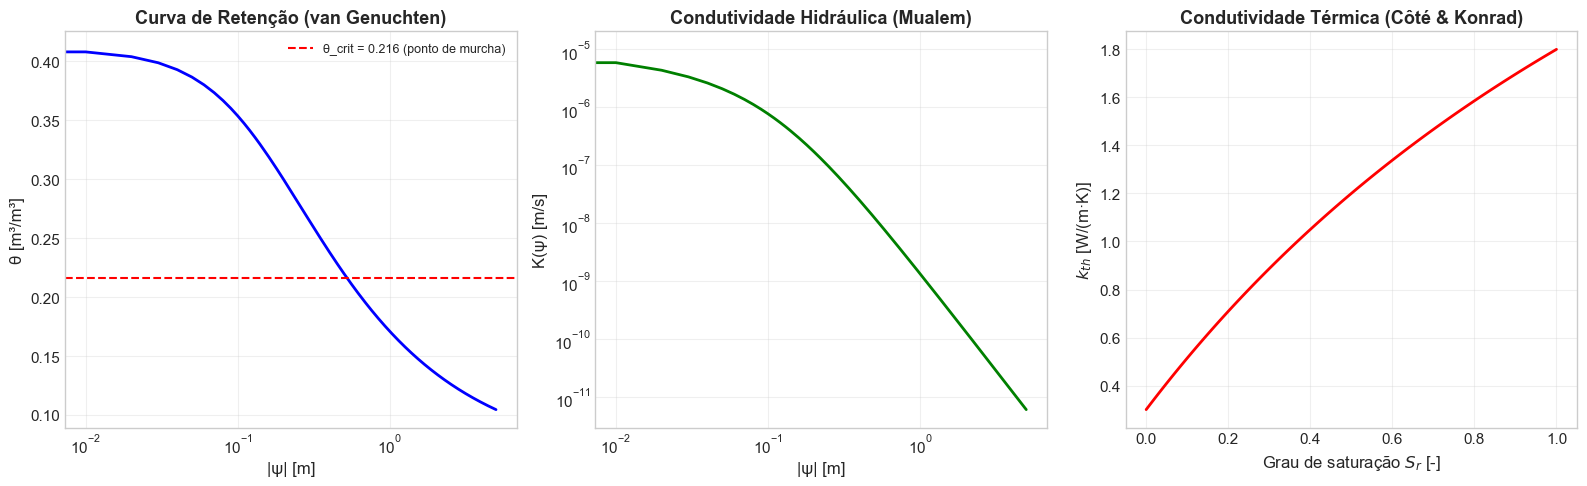


📊 Verificação:
  • θ(ψ=0) = 0.410 m³/m³ (deve ser θ_s=0.41)
  • θ(ψ=-5) = 0.105 m³/m³ (≈ θ_r=0.058)
  • k_th(Sr=0) = 0.30 W/(m·K) (deve ser k_seco=0.3)
  • k_th(Sr=1) = 1.80 W/(m·K) (deve ser k_sat=1.8)

✅ Funções constitutivas verificadas


In [59]:
# ============================================================
# VERIFICAÇÃO — Curvas constitutivas
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Curva de retenção ---
psi_test = np.linspace(-5, 0, 500)
theta_test = calc_theta(psi_test)
axes[0].plot(np.abs(psi_test), theta_test, 'b-', linewidth=2)
axes[0].axhline(theta_crit, color='r', linestyle='--', linewidth=1.5,
                label=f'θ_crit = {theta_crit:.3f} (ponto de murcha)')
axes[0].set_xscale('log')
axes[0].set_xlabel('|ψ| [m]', fontsize=12)
axes[0].set_ylabel('θ [m³/m³]', fontsize=12)
axes[0].set_title('Curva de Retenção (van Genuchten)', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# --- Condutividade hidráulica ---
K_test = calc_K(psi_test)
axes[1].plot(np.abs(psi_test), K_test, 'g-', linewidth=2)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('|ψ| [m]', fontsize=12)
axes[1].set_ylabel('K(ψ) [m/s]', fontsize=12)
axes[1].set_title('Condutividade Hidráulica (Mualem)', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)

# --- Condutividade térmica (Côté & Konrad CORRIGIDO) ---
Sr_test = np.linspace(0, 1, 100)
theta_test2 = theta_r + Sr_test * (theta_s - theta_r)
k_th_test = calc_k_thermal(theta_test2)
axes[2].plot(Sr_test, k_th_test, 'r-', linewidth=2)
axes[2].set_xlabel('Grau de saturação $S_r$ [-]', fontsize=12)
axes[2].set_ylabel('$k_{th}$ [W/(m·K)]', fontsize=12)
axes[2].set_title('Condutividade Térmica (Côté & Konrad)', fontsize=13, fontweight='bold')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'\n📊 Verificação:')
print(f'  • θ(ψ=0) = {calc_theta(np.array([0.0]))[0]:.3f} m³/m³ (deve ser θ_s={theta_s})')
print(f'  • θ(ψ=-5) = {calc_theta(np.array([-5.0]))[0]:.3f} m³/m³ (≈ θ_r={theta_r})')
print(f'  • k_th(Sr=0) = {calc_k_thermal(np.array([theta_r]))[0]:.2f} W/(m·K) (deve ser k_seco={k_seco})')
print(f'  • k_th(Sr=1) = {calc_k_thermal(np.array([theta_s]))[0]:.2f} W/(m·K) (deve ser k_sat={k_sat})')
print(f'\n✅ Funções constitutivas verificadas')

---
## 📐 Seção 3: Formulação Matemática

### 3.1 Equação de Richards 1D (forma mista)

$$C(\psi)\frac{\partial \psi}{\partial t} = \frac{\partial}{\partial z}\left[K(\psi)\left(\frac{\partial \psi}{\partial z} + 1\right)\right] - S_{root}(z, \theta)$$

onde $S_{root}$ é o termo de extração por raízes (modelo de Feddes).

### 3.2 Extração por Raízes (Feddes et al., 1978)

$$S_{root}(z, \theta) = ET_0 \cdot r(z) \cdot f(\theta)$$

onde:
- $r(z) = \beta_{root} \cdot e^{-\beta_{root} z}$ é a densidade de raízes (normalizada)
- $f(\theta) = \min\left(1, \frac{\theta - \theta_r}{\theta_{crit} - \theta_r}\right)$ é o fator de estresse hídrico

### 3.3 Equação de Calor com $k(\theta)$ variável

$$C_T(\theta)\frac{\partial T}{\partial t} = \frac{\partial}{\partial z}\left[k_{th}(\theta)\frac{\partial T}{\partial z}\right]$$

### 3.4 Condição de Contorno na Superfície (Balanço de Energia)

$$q_{surf} = \alpha_s R_s + \varepsilon_s \sigma (T_{ceu}^4 - T_s^4) + h_{conv}(T_{ar} - T_s)$$

onde a **temperatura do céu** é estimada por Brutsaert (1975):

$$T_{ceu} = T_{ar} \cdot \varepsilon_{atm}^{1/4}$$

### 3.5 Modelo de Côté & Konrad (CORRIGIDO)

$$K_e = \frac{\kappa \, S_r}{1 + (\kappa - 1)\,S_r}$$

$$k_{th} = k_{seco} + K_e\,(k_{sat} - k_{seco})$$

> 📖 **Referência:** Richards (1931); Feddes et al. (1978); Brutsaert (1975); Côté & Konrad (2005); Lugon Jr. et al. (2026), Cap. 8, Seções 8.5–8.7.

---
## ⚡ Seção 4: Critério Numérico e Estabilidade

> 💡 **Observação:** Ambos os esquemas são **implícitos**, portanto incondicionalmente estáveis. Os critérios de adequação são:

1. **Número de Fourier térmico:** $r_T = k_{max} \Delta t / (C_{min} \Delta z^2)$
2. **Resolução temporal:** Δt = 5 min → 288 passos/dia (captura adequadamente o ciclo diurno)
3. **Resolução espacial:** Δz = 5 cm → profundidade de penetração diurna (~20 cm) resolvida com 4 nós
4. **Conservação:** O nó da superfície (i=0) está DENTRO do sistema linear, garantindo conservação exata de energia

In [60]:
# ============================================================
# CRITÉRIO NUMÉRICO
# ============================================================

# Número de Fourier térmico (caso mais desfavorável: solo saturado)
C_min = C_s + theta_r * rho_w * c_p_w   # Capacidade mínima [J/(m³·K)]
r_T = k_sat * dt / (C_min * dz**2)      # Número de Fourier térmico [-]

# Número de Fourier hidráulico
r_H = K_s * dt / dz**2                  # Número de Fourier hidráulico [-]

# Validação da profundidade de penetração
k_medio = 0.5 * (k_seco + k_sat)
alpha_medio = k_medio / (rho_b * c_p_s + theta_s * rho_w * c_p_w)
omega_diurno = 2.0 * np.pi / 86400.0
omega_anual = 2.0 * np.pi / (365.0 * 86400.0)
d_pen_diurna = np.sqrt(2.0 * alpha_medio / omega_diurno)
d_pen_anual = np.sqrt(2.0 * alpha_medio / omega_anual)

print('⚡ CRITÉRIO NUMÉRICO')
print('=' * 50)
print(f'  • r_T (térmico) = {r_T:.2f}')
print(f'  • r_H (hidráulico) = {r_H:.4f}')
print(f'  • Esquema: IMPLÍCITO (incondicionalmente estável)')
print(f'  • Resolução temporal: Δt = {dt/60:.0f} min ({int(86400/dt)} passos/dia)')
print(f'  • Resolução espacial: Δz = {dz*100:.0f} cm')
print(f'\n📏 Profundidade de penetração teórica:')
print(f'  • Diurna: d = {d_pen_diurna:.2f} m')
print(f'  • Anual: d = {d_pen_anual:.2f} m')
print(f'  • Domínio H = {H} m')
print(f'\n✅ Critérios adequados para simulação')

⚡ CRITÉRIO NUMÉRICO
  • r_T (térmico) = 0.15
  • r_H (hidráulico) = 1.2000
  • Esquema: IMPLÍCITO (incondicionalmente estável)
  • Resolução temporal: Δt = 5 min (288 passos/dia)
  • Resolução espacial: Δz = 5 cm

📏 Profundidade de penetração teórica:
  • Diurna: d = 0.10 m
  • Anual: d = 1.90 m
  • Domínio H = 3.0 m

✅ Critérios adequados para simulação


---
## 🌪️ Seção 5: Condições de Entrada (Forçamento Atmosférico)

### Radiação Solar (ciclo diurno)

$$R_s(t) = R_s^{max} \cdot \max\left[0, \sin\left(\frac{\pi(t_{hora} - 6)}{12}\right)\right]$$

### Temperatura do Ar (ciclo senoidal)

$$T_{ar}(t) = 25 + 10 \cdot \sin\left(\frac{\pi(t_{hora} - 6)}{12}\right)$$

### Precipitação (MODIFICADA)

Eventos nos dias 3, 15 e 27 (mais espaçados), intensidade 3 mm/h (reduzida), duração 6 h.

### Evapotranspiração (MODIFICADA)

ET₀ = 10 mm/dia, das 5h às 20h (15 h/dia), com extração distribuída por raízes até 60 cm.

> 💡 **Observação:** A temperatura do céu é calculada pela emissividade atmosférica (Brutsaert, 1975), que depende da nebulosidade. Em céu claro, $\varepsilon_{atm} = 0{,}75$; em céu nublado, $\varepsilon_{atm} = 0{,}95$.

In [61]:
# ============================================================
# FUNÇÕES DE FORÇAMENTO ATMOSFÉRICO
# ============================================================

def get_weather(t):
    """
    Retorna forçamento atmosférico para um dado instante.

    Parameters
    ----------
    t : float
        Tempo em segundos [s].

    Returns
    -------
    tuple
        (Rs, T_ar, T_ceu) — radiação solar [W/m²], temperatura do ar [°C],
        temperatura do céu [°C].

    Notes
    -----
    Temperatura do céu via Brutsaert (1975):
    T_ceu = T_ar * epsilon_atm^(1/4)
    """
    t_hr = (t % 86400.0) / 3600.0   # Hora do dia (0 a 24)

    # 1. Radiação solar (06h às 18h)
    if 6.0 <= t_hr <= 18.0:
        Rs = 800.0 * np.sin(np.pi * (t_hr - 6.0) / 12.0)
    else:
        Rs = 0.0

    # 2. Temperatura do ar (ciclo senoidal, pico ~15h)
    T_ar = 25.0 + 10.0 * np.sin(np.pi * (t_hr - 6.0) / 12.0)

    # 3. Nebulosidade (simplificada: dia nublado a cada 7 dias)
    dia = t / 86400.0
    if int(dia) % 7 == 3:   # Dia nublado
        epsilon_atm = 0.95
    else:
        epsilon_atm = 0.75

    # 4. Temperatura do Céu via Brutsaert (1975)
    T_ar_K = T_ar + 273.15
    T_ceu_K = T_ar_K * (epsilon_atm ** 0.25)
    T_ceu = T_ceu_K - 273.15

    return Rs, T_ar, T_ceu


def extracao_raizes(z, theta, ET_potencial):
    """
    Extração de água pelas raízes distribuída no perfil.
    Modelo de Feddes et al. (1978) simplificado.

    Parameters
    ----------
    z : ndarray
        Profundidades [m].
    theta : ndarray
        Umidade atual [m³/m³].
    ET_potencial : float
        Taxa potencial de ET [m/s].

    Returns
    -------
    ndarray
        Taxa de extração em cada nó [m³/(m³·s)].
    """
    # Densidade de raízes decai exponencialmente com a profundidade
    raiz = beta_root * np.exp(-beta_root * z)
    raiz[z > z_root] = 0.0

    # Normalizar para que integral = 1
    integral = np.trapz(raiz, z)
    if integral > 0:
        raiz_norm = raiz / integral
    else:
        raiz_norm = np.zeros_like(raiz)

    # Fator de estresse hídrico (Feddes simplificado)
    # ET potencial quando θ > θ_crit; ET → 0 quando θ → θ_r
    fator_estresse = np.clip(
        (theta - theta_r) / (theta_crit - theta_r + 1e-10), 0.0, 1.0)

    # Extração distribuída [m³/(m³·s)]
    extracao = ET_potencial * raiz_norm * fator_estresse

    return extracao


def get_q_surf_agua(t, theta_superficie):
    """
    Fluxo líquido de água na superfície (chuva - ET).
    MODIFICADO: ET aumentada e dependente da umidade.

    Parameters
    ----------
    t : float
        Tempo [s].
    theta_superficie : float
        Umidade na superfície [m³/m³] (do passo anterior).

    Returns
    -------
    float
        Fluxo líquido [m/s]. Positivo = infiltração.
    """
    dia = t / 86400.0
    t_hr = (t % 86400.0) / 3600.0

    # Chuva (MODIFICADA: dias 3, 15, 27; 3 mm/h)
    q_chuva = 0.0
    for dia_chuva in eventos_chuva:
        if dia_chuva <= dia < dia_chuva + duracao_chuva:
            q_chuva = intensidade_chuva

    # ET potencial (MODIFICADA: 10 mm/dia, 05h-20h)
    ET_potencial = 0.0
    if t_ini_ET <= t_hr <= t_fim_ET:
        ET_potencial = ET0 * np.sin(np.pi * (t_hr - t_ini_ET) / (t_fim_ET - t_ini_ET))

    # Fator de estresse hídrico (limitação pela umidade superficial)
    fator = np.clip(
        (theta_superficie - theta_r) / (theta_crit - theta_r + 1e-10), 0.0, 1.0)

    q_ET = ET_potencial * fator

    return q_chuva - q_ET


print('✅ Funções de forçamento atmosférico implementadas')
print(f'  • Radiação solar: R_s_max = 800 W/m² (6h-18h)')
print(f'  • Temperatura do ar: 15°C a 35°C (ciclo diurno)')
print(f'  • Temperatura do céu: Brutsaert (1975)')
print(f'  • Chuva: dias {eventos_chuva} (3 mm/h, 6h)')
print(f'  • Evapotranspiração: ET₀ = 10 mm/dia ({t_ini_ET:.0f}h-{t_fim_ET:.0f}h)')
print(f'  • Extração por raízes: até z = {z_root} m (Feddes)')

✅ Funções de forçamento atmosférico implementadas
  • Radiação solar: R_s_max = 800 W/m² (6h-18h)
  • Temperatura do ar: 15°C a 35°C (ciclo diurno)
  • Temperatura do céu: Brutsaert (1975)
  • Chuva: dias [3.0, 15.0, 27.0] (3 mm/h, 6h)
  • Evapotranspiração: ET₀ = 10 mm/dia (5h-20h)
  • Extração por raízes: até z = 0.6 m (Feddes)


---
## 🧮 Seção 6: Implementação Numérica

### Correções aplicadas nesta versão:

1. **Nó superficial (i=0) DENTRO do sistema linear** de Richards → conservação de massa
2. **Fórmula de Côté & Konrad corrigida** → $K_e = \kappa S_r / (1 + (\kappa-1)S_r)$
3. **Capacidade térmica $C_T$ com umidade atual** → inércia térmica correta
4. **Condição inicial mais realista** → perfil de umidade parcial
5. **Extração por raízes distribuída** → modelo de Feddes
6. **ET dependente da umidade** → feedback não-linear

In [62]:
# ============================================================
# SOLVER: Equação de Richards 1D (Esquema Implícito com Picard)
# CORREÇÃO: O nó da superfície (i=0) está DENTRO do sistema linear
# CORREÇÃO: Termo de extração por raízes incluído
# ============================================================

def solver_richards(psi_old, theta_old, dt, dz, Nz, q_surf, t_atual):
    """
    Resolve um passo de tempo da equação de Richards.
    O nó da superfície (i=0) está DENTRO do sistema linear.
    Inclui termo de extração por raízes (Feddes).

    Parameters
    ----------
    psi_old : ndarray
        Potencial matricial no passo anterior [m].
    theta_old : ndarray
        Umidade no passo anterior [m³/m³].
    dt : float
        Passo de tempo [s].
    dz : float
        Espaçamento espacial [m].
    Nz : int
        Número de nós.
    q_surf : float
        Fluxo líquido na superfície [m/s].
    t_atual : float
        Tempo atual [s].

    Returns
    -------
    tuple
        (psi_new, theta_new, convergiu, n_iter)
    """
    psi = psi_old.copy()
    tol_picard = 1e-6
    max_iter = 20

    # Calcular extração por raízes (baseada no perfil atual)
    t_hr = (t_atual % 86400.0) / 3600.0
    ET_potencial = 0.0
    if t_ini_ET <= t_hr <= t_fim_ET:
        ET_potencial = ET0 * np.sin(np.pi * (t_hr - t_ini_ET) / (t_fim_ET - t_ini_ET))
    S_root = extracao_raizes(z, theta_old, ET_potencial)

    for n_iter in range(max_iter):
        theta = calc_theta(psi)
        C = calc_dtheta_dpsi(psi)
        K = calc_K(psi)

        # Condutividade nas interfaces (média harmônica)
        K_interface = np.zeros(Nz - 1)
        for i in range(Nz - 1):
            if K[i] + K[i+1] > 0:
                K_interface[i] = 2.0 * K[i] * K[i+1] / (K[i] + K[i+1])
            else:
                K_interface[i] = 0.0

        coef = dt / dz**2

        # Sistema para nós 0 a Nz-2 (base é Dirichlet)
        N_int = Nz - 1
        main_diag = np.zeros(N_int)
        lower_diag = np.zeros(N_int - 1)
        upper_diag = np.zeros(N_int - 1)
        b_vec = np.zeros(N_int)

        # Nó 0 (superfície) — volume de controle de meia espessura
        C_surf = max(C[0], 1e-10)
        main_diag[0] = C_surf * dz / (2.0 * dt) + K_interface[0] / dz
        upper_diag[0] = -K_interface[0] / dz
        b_vec[0] = C_surf * dz / (2.0 * dt) * psi[0] + q_surf

        # Nós internos (1 a Nz-2)
        for i in range(1, N_int):
            main_diag[i] = C[i] + coef * (K_interface[i-1] + K_interface[i])
            b_vec[i] = C[i] * psi[i]
            if i > 0:
                lower_diag[i-1] = -coef * K_interface[i-1]
            if i < N_int - 1:
                upper_diag[i] = -coef * K_interface[i]

        # Contribuição da BC de Dirichlet na base
        b_vec[-1] += coef * K_interface[-1] * psi_base

        # Subtrair extração por raízes (termo sumidouro)
        for i in range(N_int):
            b_vec[i] -= S_root[i] * dt

        # Resolver
        A_mat = diags([lower_diag, main_diag, upper_diag], [-1, 0, 1],
                      shape=(N_int, N_int), format='csc')
        psi_new_int = spsolve(A_mat, b_vec)

        # Montar vetor completo
        psi_new = np.zeros(Nz)
        psi_new[0:-1] = psi_new_int
        psi_new[-1] = psi_base

        theta_new = calc_theta(psi_new)

        err = np.max(np.abs(psi_new - psi))
        if err < tol_picard:
            return psi_new, theta_new, True, n_iter + 1

        psi = psi_new

    return psi, calc_theta(psi), False, max_iter


print('✅ Solver de Richards implementado (nó 0 DENTRO do sistema + extração por raízes)')

✅ Solver de Richards implementado (nó 0 DENTRO do sistema + extração por raízes)


In [63]:
# ============================================================
# SOLVER: Equação de Calor (Esquema Implícito)
# CORREÇÃO: C_T usa umidade ATUAL (não fixa)
# ============================================================

def solver_termico(T_old, k_profile, theta_atual, dt, dz, Nz, t_next, T_base_val):
    """
    Resolve a equação de calor 1D por esquema implícito.
    O nó da superfície (i=0) está DENTRO do sistema linear.

    Parameters
    ----------
    T_old : ndarray
        Temperatura no passo anterior [°C].
    k_profile : ndarray
        Condutividade térmica em cada nó [W/(m·K)].
    theta_atual : ndarray
        Umidade atual em cada nó [m³/m³] (CORREÇÃO).
    dt : float
        Passo de tempo [s].
    dz : float
        Espaçamento espacial [m].
    Nz : int
        Número de nós.
    t_next : float
        Tempo no próximo passo [s].
    T_base_val : float
        Temperatura na base [°C].

    Returns
    -------
    tuple
        (T_new, convergiu)
    """
    # 1. Condutividade nas interfaces
    k_interface = 0.5 * (k_profile[:-1] + k_profile[1:])

    # 2. Capacidade volumétrica com umidade ATUAL (CORREÇÃO)
    C_T = calc_C_thermal(theta_atual)

    # 3. Forçamento atmosférico
    Rs, T_ar, T_ceu = get_weather(t_next)

    # 4. BC superficial não-linear (Picard interno)
    T_surf_guess = T_old[0]
    tol_surf = 1e-4
    max_iter_surf = 10

    for it_s in range(max_iter_surf):
        T_surf_K = T_surf_guess + 273.15
        T_ceu_K = T_ceu + 273.15

        q_solar = alpha_s * Rs
        q_rad = epsilon_s * sigma_SB * (T_ceu_K**4 - T_surf_K**4)
        q_conv_s = h_conv * (T_ar - T_surf_guess)
        q_surf_total = q_solar + q_rad + q_conv_s

        # 5. Montar sistema linear (nós 0 a Nz-2, base é Dirichlet)
        N_int = Nz - 1
        coef = dt / dz**2

        main_diag = np.zeros(N_int)
        lower_diag = np.zeros(N_int - 1)
        upper_diag = np.zeros(N_int - 1)
        b_vec = np.zeros(N_int)

        # Nó 0 (superfície) — volume de controle de meia espessura
        coef_cap_0 = C_T[0] * dz / (2.0 * dt)
        main_diag[0] = coef_cap_0 + k_interface[0] / dz
        upper_diag[0] = -k_interface[0] / dz
        b_vec[0] = coef_cap_0 * T_old[0] + q_surf_total

        # Nós internos (1 a Nz-2)
        for i in range(1, N_int):
            coef_cap_i = C_T[i] / dt
            main_diag[i] = coef_cap_i + coef * (k_interface[i-1] + k_interface[i])
            b_vec[i] = coef_cap_i * T_old[i]
            if i > 0:
                lower_diag[i-1] = -coef * k_interface[i-1]
            if i < N_int - 1:
                upper_diag[i] = -coef * k_interface[i]

        # Contribuição da BC de Dirichlet na base
        b_vec[-1] += coef * k_interface[-1] * T_base_val

        # 6. Resolver o sistema linear
        A_mat = diags([lower_diag, main_diag, upper_diag], [-1, 0, 1], format='csc')
        T_new_interior = spsolve(A_mat, b_vec)

        # 7. Verificar convergência da BC superficial
        T_surf_new = T_new_interior[0]
        if abs(T_surf_new - T_surf_guess) < tol_surf:
            break
        T_surf_guess = T_surf_new

    # 8. Montar o vetor final de temperatura
    T_new = np.zeros(Nz)
    T_new[0:-1] = T_new_interior
    T_new[-1] = T_base_val   # Condição de Dirichlet na base

    return T_new, True


print('✅ Solver térmico implementado (C_T com umidade atual)')

✅ Solver térmico implementado (C_T com umidade atual)


In [64]:
# ============================================================
# SIMULAÇÃO ACOPLADA — Loop principal
# ============================================================

t_inicio_sim = time.time()

# --- Condição inicial (CORREÇÃO: perfil mais realista) ---
psi_init = np.zeros(Nz)
for i in range(Nz):
    psi_init[i] = -0.5 - 0.3 * (1.0 - z[i] / H)   # Perfil parcialmente úmido

theta_init = calc_theta(psi_init)
T_init = np.full(Nz, T_base)   # Temperatura uniforme

# --- Arrays de armazenamento ---
T_hist = np.zeros((Nt, Nz))
theta_hist = np.zeros((Nt, Nz))
psi_hist = np.zeros((Nt, Nz))
k_hist = np.zeros((Nt, Nz))

T_hist[0, :] = T_init
theta_hist[0, :] = theta_init
psi_hist[0, :] = psi_init
k_hist[0, :] = calc_k_thermal(theta_init)

# --- Estatísticas de convergência ---
acopl_iter_hist = np.zeros(Nt)
rich_iter_hist = np.zeros(Nt)
rich_conv_hist = np.zeros(Nt)

print('=' * 70)
print('  INICIANDO SIMULAÇÃO ACOPLADA TERMO-HÍDRICA (30 DIAS)')
print('=' * 70)
print(f'  Domínio: 0 a {H} m | T_base = {T_base}°C | ψ_base = {psi_base} m')
print(f'  Passo de tempo: {dt:.0f} s | Acoplamento: até {max_acopl_iter} iterações')
print(f'  Umidade inicial: θ(0) = {theta_init[0]:.3f}, θ(H) = {theta_init[-1]:.3f} m³/m³')
print(f'  ET₀ = 10 mm/dia | Chuva: dias {eventos_chuva}')
print('-' * 70)

# --- Loop temporal ---
for n in range(Nt - 1):
    t_current = t_sec[n]
    t_next = t_sec[n + 1]

    psi_n = psi_hist[n, :].copy()
    theta_n = theta_hist[n, :].copy()
    T_n = T_hist[n, :].copy()

    # Fluxo de água na superfície (com feedback da umidade)
    q_agua = get_q_surf_agua(t_next, theta_n[0])

    # Iteração de acoplamento (Picard)
    convergiu = False
    for it_acopl in range(max_acopl_iter):
        # 1. Resolver Richards (com extração por raízes)
        psi_new, theta_new, conv_rich, n_iter_rich = solver_richards(
            psi_n, theta_n, dt, dz, Nz, q_agua, t_next)

        # 2. Calcular condutividade térmica atualizada
        k_profile = calc_k_thermal(theta_new)

        # 3. Resolver equação de calor (com umidade ATUAL)
        T_new, _ = solver_termico(T_n, k_profile, theta_new, dt, dz, Nz, t_next, T_base)

        # 4. Verificar convergência do acoplamento
        err_T = np.max(np.abs(T_new - T_n))
        err_psi = np.max(np.abs(psi_new - psi_n))

        if err_T < tol_acopl and err_psi < tol_acopl:
            convergiu = True
            break

        psi_n = psi_new.copy()
        theta_n = theta_new.copy()
        T_n = T_new.copy()

    # Atualizar históricos
    if convergiu:
        acopl_iter_hist[n+1] = it_acopl + 1
    else:
        acopl_iter_hist[n+1] = max_acopl_iter
    rich_iter_hist[n+1] = n_iter_rich
    rich_conv_hist[n+1] = 1.0 if conv_rich else 0.0

    psi_hist[n+1, :] = psi_n
    theta_hist[n+1, :] = theta_n
    T_hist[n+1, :] = T_n
    k_hist[n+1, :] = calc_k_thermal(theta_n)

    # Progresso
    if (n + 1) % (Nt // 10) == 0:
        print(f'  Progresso: {100*(n+1)/(Nt-1):5.1f}% | Dia {t_dias[n+1]:5.1f}')

t_cpu_sim = time.time() - t_inicio_sim

print('=' * 70)
print('✅ SIMULAÇÃO CONCLUÍDA!')
print(f'  Média de iterações de acoplamento por passo: {np.mean(acopl_iter_hist[1:]):.2f}')
print(f'  Média de iterações de Richards por passo: {np.mean(rich_iter_hist[1:]):.2f}')
print(f'  Taxa de convergência de Richards: {100*np.mean(rich_conv_hist[1:]):.1f}%')
print('=' * 70)
print(f'\n⏱️ Tempo de CPU: {t_cpu_sim:.2f} s')

  INICIANDO SIMULAÇÃO ACOPLADA TERMO-HÍDRICA (30 DIAS)
  Domínio: 0 a 3.0 m | T_base = 15.0°C | ψ_base = 0.0 m
  Passo de tempo: 300 s | Acoplamento: até 5 iterações
  Umidade inicial: θ(0) = 0.185, θ(H) = 0.220 m³/m³
  ET₀ = 10 mm/dia | Chuva: dias [3.0, 15.0, 27.0]
----------------------------------------------------------------------
  Progresso:  10.0% | Dia   3.0
  Progresso:  20.0% | Dia   6.0
  Progresso:  30.0% | Dia   9.0
  Progresso:  40.0% | Dia  12.0
  Progresso:  50.0% | Dia  15.0
  Progresso:  60.0% | Dia  18.0
  Progresso:  70.0% | Dia  21.0
  Progresso:  80.0% | Dia  24.0
  Progresso:  90.0% | Dia  27.0
  Progresso: 100.0% | Dia  30.0
✅ SIMULAÇÃO CONCLUÍDA!
  Média de iterações de acoplamento por passo: 5.00
  Média de iterações de Richards por passo: 13.15
  Taxa de convergência de Richards: 36.0%

⏱️ Tempo de CPU: 473.99 s


---
## 📊 Seção 7: Visualização

Os gráficos abaixo mostram três fenômenos fundamentais:

1. **Aquecimento diurno da superfície:** A radiação solar aquece a camada superficial durante o dia, e a superfície esfria à noite por radiação de onda longa.

2. **Isolamento térmico com profundidade:** A onda térmica diurna é amortecida exponencialmente. A ~15 cm, a oscilação diária já é quase imperceptível.

3. **Temperatura constante em profundidade:** A 3 m, a temperatura permanece constante em ~15°C (média anual), pois a onda térmica anual (~3,87 m) ainda não penetrou completamente.

4. **Variação de umidade com ET intensificada:** A umidade varia significativamente entre eventos de chuva, com secagem progressiva por evapotranspiração.

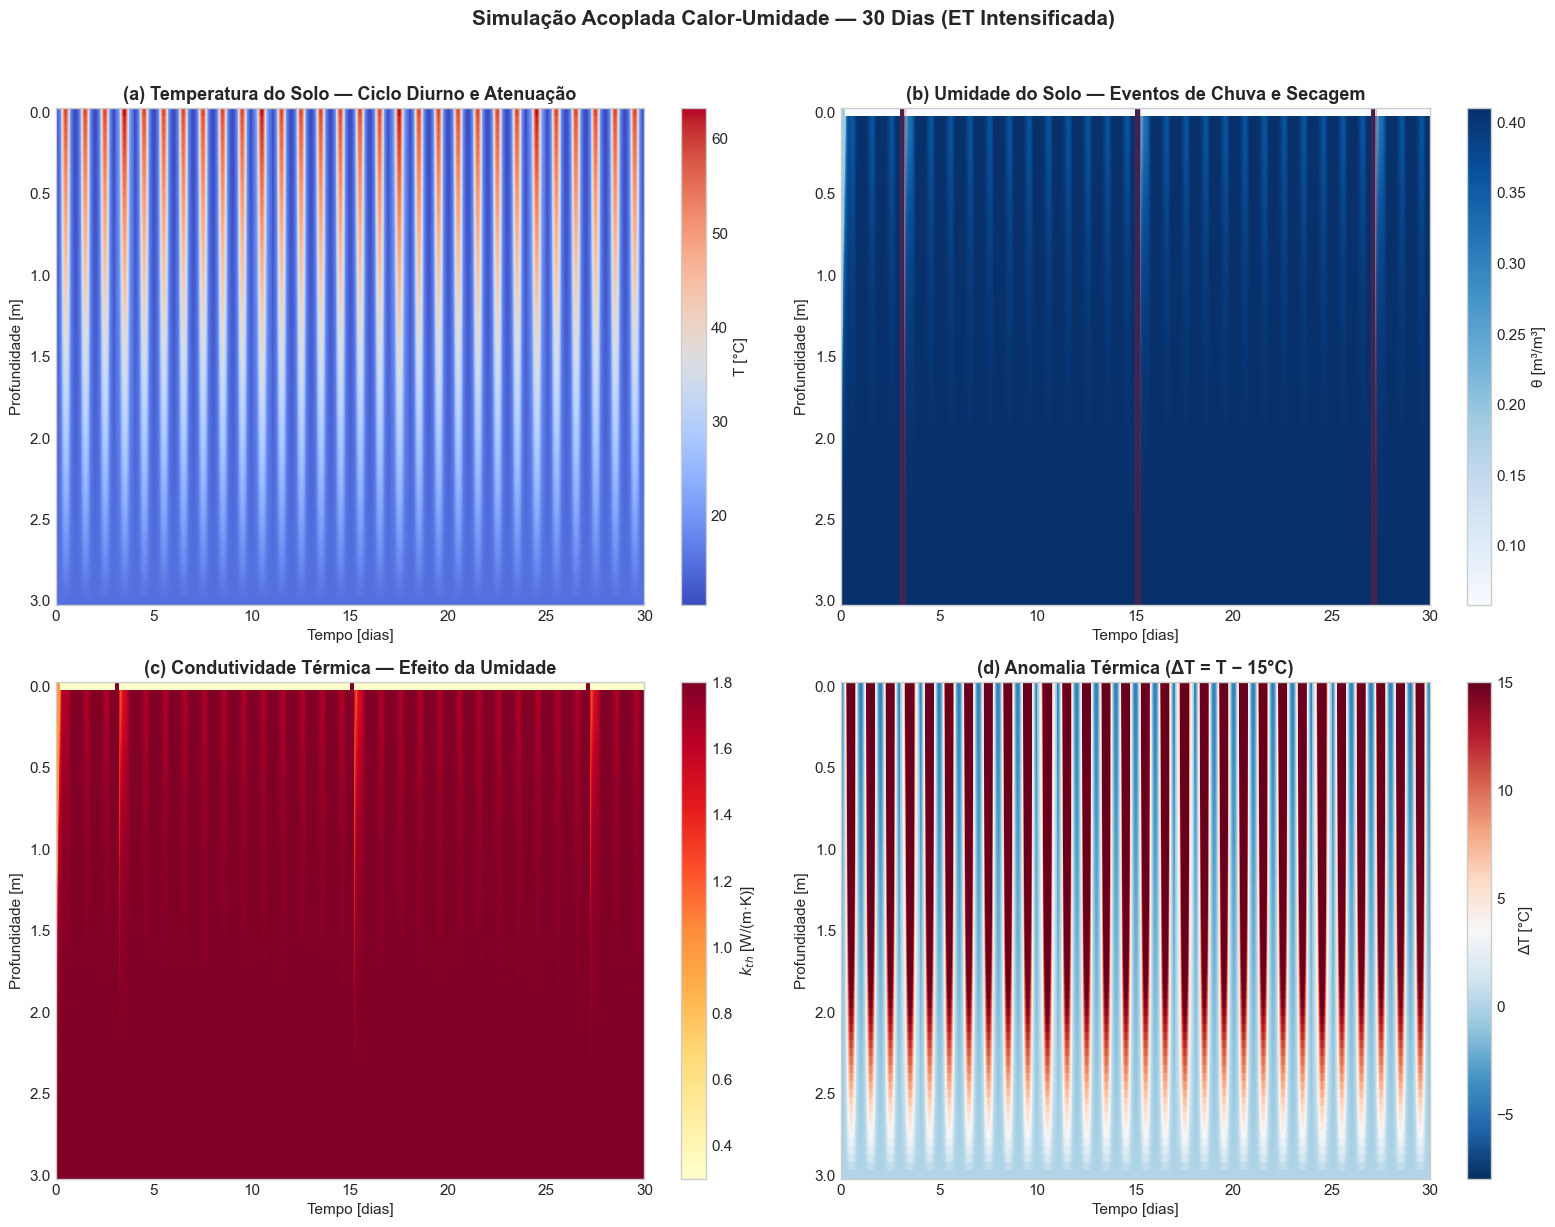

In [65]:
# ============================================================
# GRÁFICO 1: Heatmaps — Temperatura, Umidade, Condutividade, Anomalia
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- (a) Temperatura do solo ---
ax = axes[0, 0]
c1 = ax.pcolormesh(t_dias, z, T_hist.T, cmap='coolwarm', shading='auto')
plt.colorbar(c1, ax=ax, label='T [°C]')
ax.set_xlabel('Tempo [dias]', fontsize=11)
ax.set_ylabel('Profundidade [m]', fontsize=11)
ax.set_title('(a) Temperatura do Solo — Ciclo Diurno e Atenuação',
             fontsize=13, fontweight='bold')
ax.invert_yaxis()

# --- (b) Umidade do solo ---
ax = axes[0, 1]
c2 = ax.pcolormesh(t_dias, z, theta_hist.T, cmap='Blues', shading='auto')
plt.colorbar(c2, ax=ax, label='θ [m³/m³]')
ax.set_xlabel('Tempo [dias]', fontsize=11)
ax.set_ylabel('Profundidade [m]', fontsize=11)
ax.set_title('(b) Umidade do Solo — Eventos de Chuva e Secagem',
             fontsize=13, fontweight='bold')
ax.invert_yaxis()
for dia_chuva in eventos_chuva:
    ax.axvspan(dia_chuva, dia_chuva + duracao_chuva, color='red', alpha=0.2)

# --- (c) Condutividade térmica ---
ax = axes[1, 0]
c3 = ax.pcolormesh(t_dias, z, k_hist.T, cmap='YlOrRd', shading='auto')
plt.colorbar(c3, ax=ax, label='$k_{th}$ [W/(m·K)]')
ax.set_xlabel('Tempo [dias]', fontsize=11)
ax.set_ylabel('Profundidade [m]', fontsize=11)
ax.set_title('(c) Condutividade Térmica — Efeito da Umidade',
             fontsize=13, fontweight='bold')
ax.invert_yaxis()

# --- (d) Anomalia térmica ---
ax = axes[1, 1]
T_anomalia = T_hist - T_base
c4 = ax.pcolormesh(t_dias, z, T_anomalia.T, cmap='RdBu_r', shading='auto',
                   vmin=-8, vmax=15)
plt.colorbar(c4, ax=ax, label='ΔT [°C]')
ax.set_xlabel('Tempo [dias]', fontsize=11)
ax.set_ylabel('Profundidade [m]', fontsize=11)
ax.set_title('(d) Anomalia Térmica (ΔT = T − 15°C)',
             fontsize=13, fontweight='bold')
ax.invert_yaxis()

plt.suptitle('Simulação Acoplada Calor-Umidade — 30 Dias (ET Intensificada)',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - **(a)** A onda térmica diurna penetra ~15-20 cm. Abaixo de 0,5 m, a temperatura é praticamente constante.
> - **(b)** A umidade agora varia significativamente: aumenta após chuva (dias 3, 15, 27) e diminui progressivamente por ET.
> - **(c)** A condutividade térmica acompanha a umidade em tempo real: solo úmido conduz mais calor.
> - **(d)** A anomalia térmica mostra o "bulbo" de aquecimento diurno se propagando para baixo.

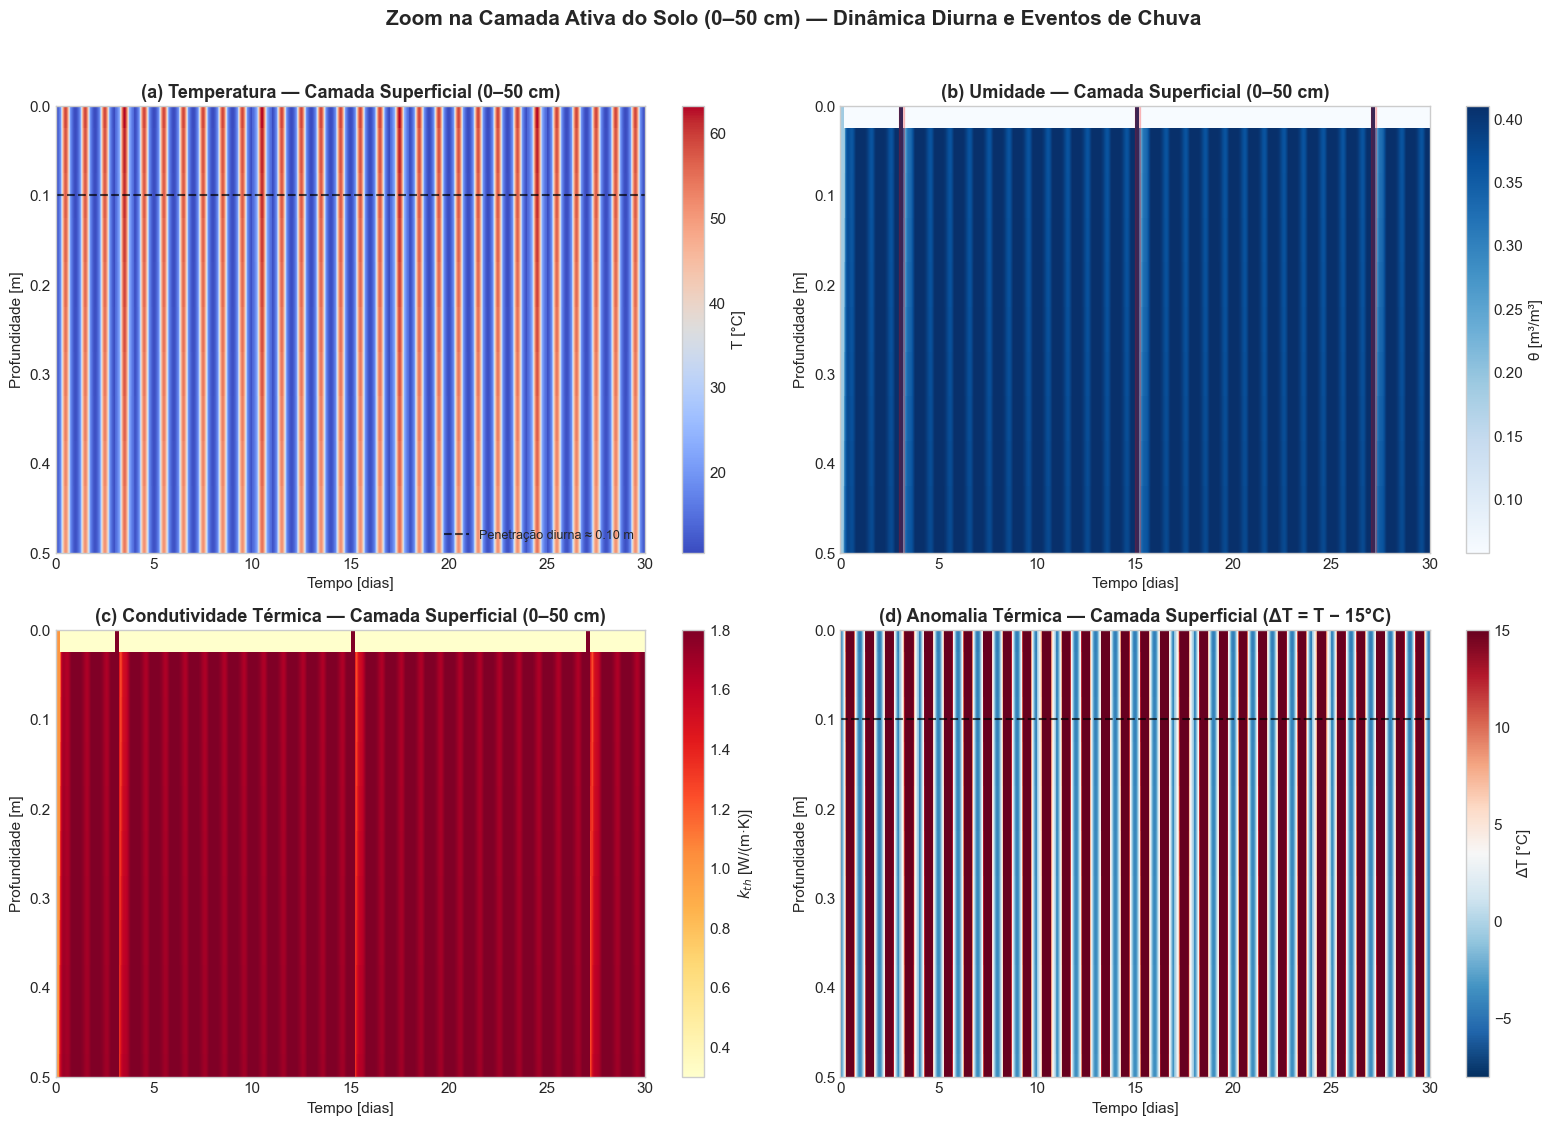

In [66]:
# ============================================================
# GRÁFICO 2: ZOOM NA CAMADA SUPERFICIAL (0 a 50 cm)
# ============================================================

z_zoom_max = 0.50   # [m]
idx_cut = int(z_zoom_max / dz) + 1

T_zoom = T_hist[:, :idx_cut]
theta_zoom = theta_hist[:, :idx_cut]
k_zoom = k_hist[:, :idx_cut]
T_anom_zoom = T_zoom - T_base

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# --- (a) Temperatura (zoom) ---
ax = axes[0, 0]
c1 = ax.pcolormesh(t_dias, z[:idx_cut], T_zoom.T,
                   cmap='coolwarm', shading='auto')
plt.colorbar(c1, ax=ax, label='T [°C]')
ax.set_xlabel('Tempo [dias]', fontsize=11)
ax.set_ylabel('Profundidade [m]', fontsize=11)
ax.set_title('(a) Temperatura — Camada Superficial (0–50 cm)',
             fontsize=13, fontweight='bold')
ax.invert_yaxis()
ax.set_ylim(z_zoom_max, 0)
ax.axhline(d_pen_diurna, color='k', linestyle='--', linewidth=1.5, alpha=0.7,
           label=f'Penetração diurna ≈ {d_pen_diurna:.2f} m')
ax.legend(fontsize=9, loc='lower right')

# --- (b) Umidade (zoom) ---
ax = axes[0, 1]
c2 = ax.pcolormesh(t_dias, z[:idx_cut], theta_zoom.T,
                   cmap='Blues', shading='auto')
plt.colorbar(c2, ax=ax, label='θ [m³/m³]')
ax.set_xlabel('Tempo [dias]', fontsize=11)
ax.set_ylabel('Profundidade [m]', fontsize=11)
ax.set_title('(b) Umidade — Camada Superficial (0–50 cm)',
             fontsize=13, fontweight='bold')
ax.invert_yaxis()
ax.set_ylim(z_zoom_max, 0)
for dia_chuva in eventos_chuva:
    ax.axvspan(dia_chuva, dia_chuva + duracao_chuva, color='red', alpha=0.2)

# --- (c) Condutividade térmica (zoom) ---
ax = axes[1, 0]
c3 = ax.pcolormesh(t_dias, z[:idx_cut], k_zoom.T,
                   cmap='YlOrRd', shading='auto')
plt.colorbar(c3, ax=ax, label='$k_{th}$ [W/(m·K)]')
ax.set_xlabel('Tempo [dias]', fontsize=11)
ax.set_ylabel('Profundidade [m]', fontsize=11)
ax.set_title('(c) Condutividade Térmica — Camada Superficial (0–50 cm)',
             fontsize=13, fontweight='bold')
ax.invert_yaxis()
ax.set_ylim(z_zoom_max, 0)

# --- (d) Anomalia térmica (zoom) ---
ax = axes[1, 1]
c4 = ax.pcolormesh(t_dias, z[:idx_cut], T_anom_zoom.T,
                   cmap='RdBu_r', shading='auto', vmin=-8, vmax=15)
plt.colorbar(c4, ax=ax, label='ΔT [°C]')
ax.set_xlabel('Tempo [dias]', fontsize=11)
ax.set_ylabel('Profundidade [m]', fontsize=11)
ax.set_title('(d) Anomalia Térmica — Camada Superficial (ΔT = T − 15°C)',
             fontsize=13, fontweight='bold')
ax.invert_yaxis()
ax.set_ylim(z_zoom_max, 0)
ax.axhline(d_pen_diurna, color='k', linestyle='--', linewidth=1.5, alpha=0.7)

plt.suptitle('Zoom na Camada Ativa do Solo (0–50 cm) — Dinâmica Diurna e Eventos de Chuva',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - **(a)** O zoom revela o padrão de "penetração em cunha" da onda térmica diurna.
> - **(b)** A umidade varia claramente: picos após chuva, secagem progressiva por ET.
> - **(c)** A condutividade térmica varia de ~0,35 (seco) a ~1,2 W/(m·K) (úmido).
> - **(d)** A anomalia térmica mostra o gradiente na camada superficial.

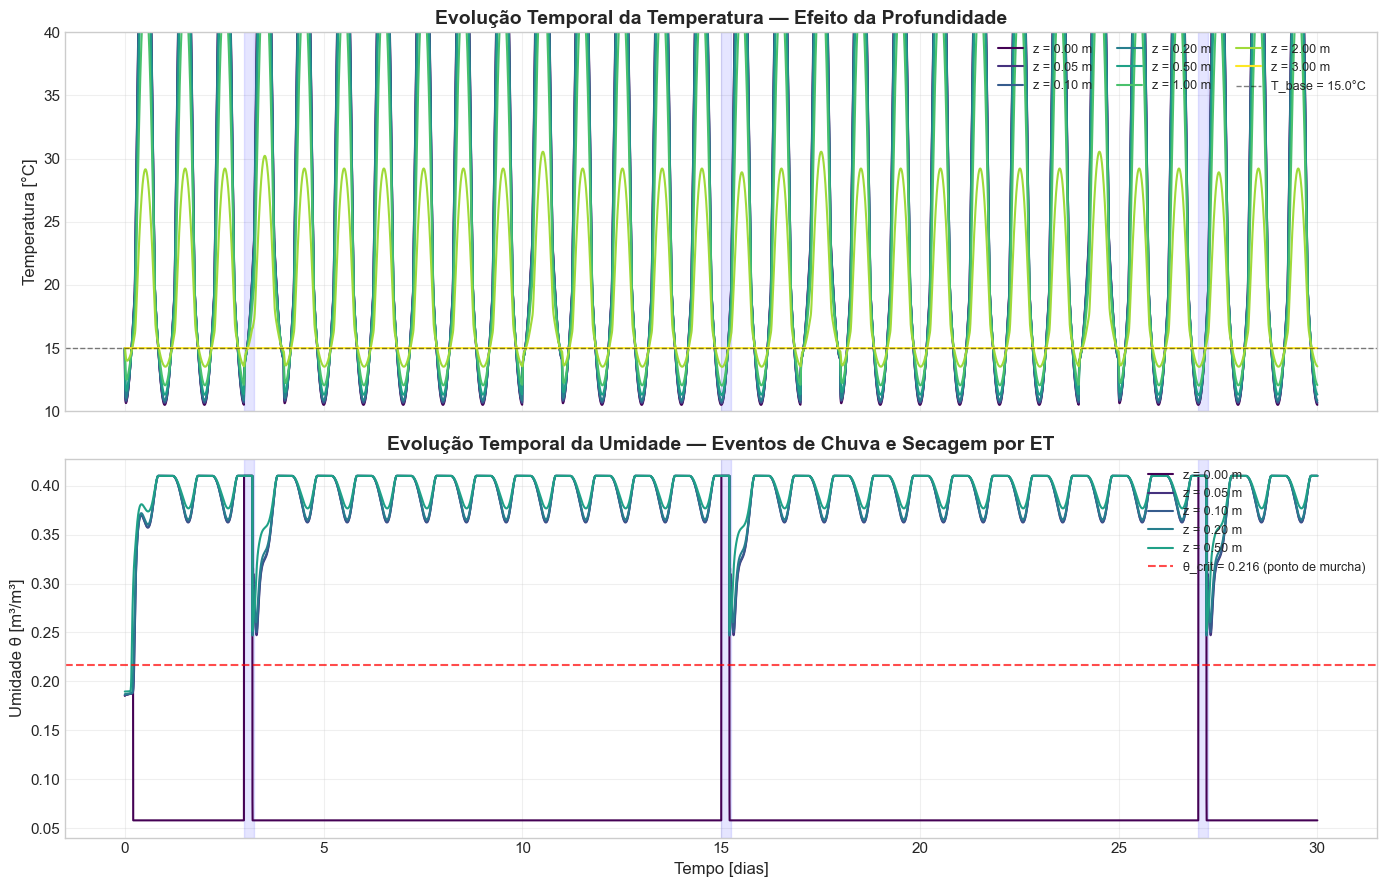

In [67]:
# ============================================================
# GRÁFICO 3: Evolução Temporal — Superfície vs. Profundidade
# ============================================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# --- Painel superior: Temperaturas em diferentes profundidades ---
profundidades = [0.0, 0.05, 0.10, 0.20, 0.50, 1.00, 2.00, 3.00]
cores_prof = plt.cm.viridis(np.linspace(0, 1, len(profundidades)))

for prof, cor in zip(profundidades, cores_prof):
    idx_z = int(prof / dz)
    ax1.plot(t_dias, T_hist[:, idx_z], color=cor, linewidth=1.5,
             label=f'z = {prof:.2f} m')

ax1.axhline(T_base, color='k', linestyle='--', linewidth=1, alpha=0.5,
            label=f'T_base = {T_base}°C')
ax1.set_ylabel('Temperatura [°C]', fontsize=12)
ax1.set_title('Evolução Temporal da Temperatura — Efeito da Profundidade',
              fontsize=14, fontweight='bold')
ax1.legend(fontsize=9, loc='upper right', ncol=3)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(10, 40)

for dia_chuva in eventos_chuva:
    ax1.axvspan(dia_chuva, dia_chuva + duracao_chuva, color='blue', alpha=0.1)

# --- Painel inferior: Umidade ---
for prof, cor in zip(profundidades[:5], cores_prof[:5]):
    idx_z = int(prof / dz)
    ax2.plot(t_dias, theta_hist[:, idx_z], color=cor, linewidth=1.5,
             label=f'z = {prof:.2f} m')

ax2.axhline(theta_crit, color='r', linestyle='--', linewidth=1.5, alpha=0.7,
            label=f'θ_crit = {theta_crit:.3f} (ponto de murcha)')
ax2.set_xlabel('Tempo [dias]', fontsize=12)
ax2.set_ylabel('Umidade θ [m³/m³]', fontsize=12)
ax2.set_title('Evolução Temporal da Umidade — Eventos de Chuva e Secagem por ET',
              fontsize=14, fontweight='bold')
ax2.legend(fontsize=9, loc='upper right')
ax2.grid(True, alpha=0.3)

for dia_chuva in eventos_chuva:
    ax2.axvspan(dia_chuva, dia_chuva + duracao_chuva, color='blue', alpha=0.1)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - **Superfície (z=0):** Oscilação diurna de ~15°C a ~35°C.
> - **z = 5-10 cm:** Oscilação reduzida (~5°C) e com atraso de fase.
> - **z ≥ 50 cm:** Temperatura praticamente constante em ~15°C.
> - **Umidade:** Picos nos dias de chuva (3, 15, 27), seguidos de secagem progressiva por ET.
> - **Ponto de murcha:** A umidade superficial pode atingir θ_crit, reduzindo a ET (feedback).

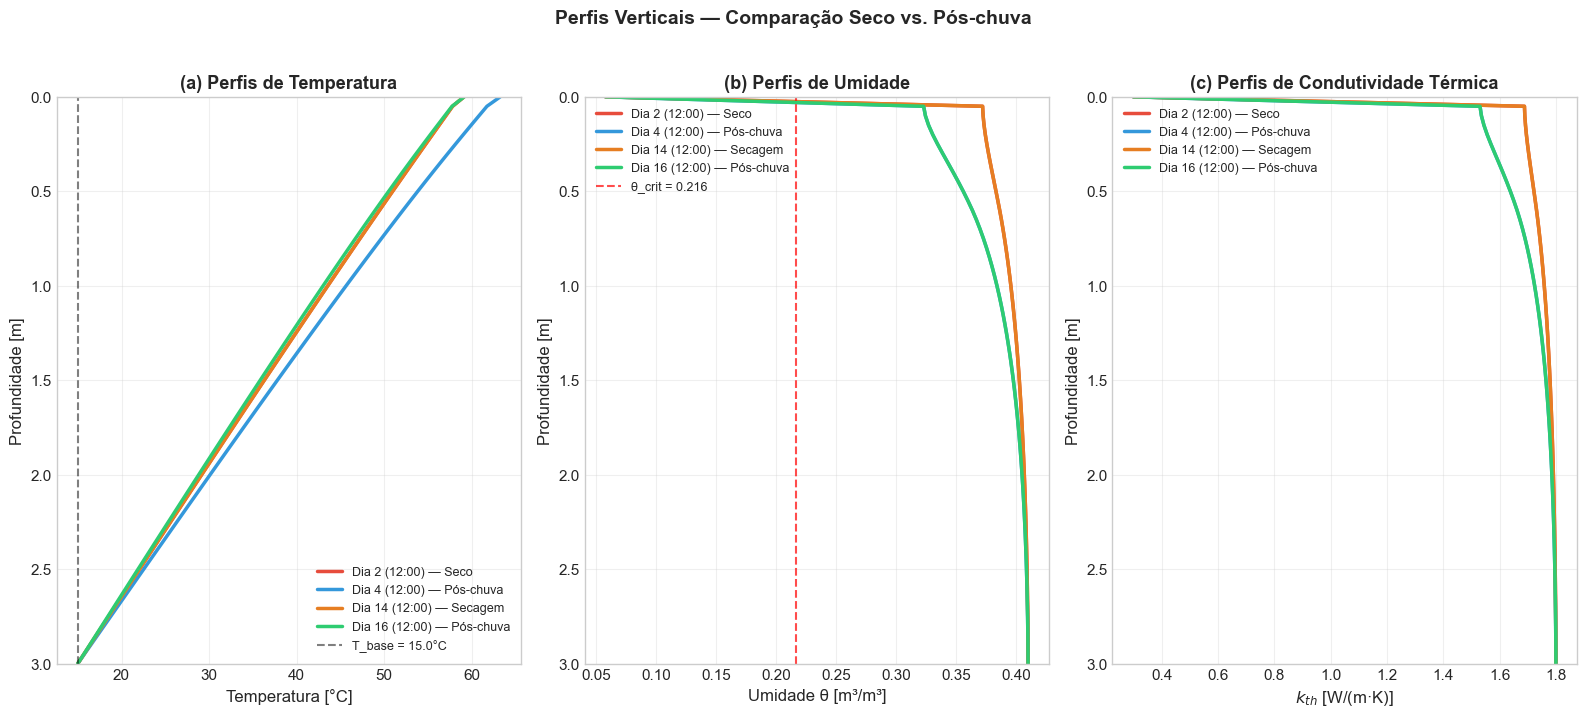

In [68]:
# ============================================================
# GRÁFICO 4: Perfis Verticais em Instantes Selecionados
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 7))

# Instantes selecionados
instantes = {
    'Dia 2 (12:00) — Seco': 1.5,
    'Dia 4 (12:00) — Pós-chuva': 3.5,
    'Dia 14 (12:00) — Secagem': 13.5,
    'Dia 16 (12:00) — Pós-chuva': 15.5,
}
cores_inst = ['#e74c3c', '#3498db', '#e67e22', '#2ecc71']

# --- (a) Perfis de temperatura ---
ax = axes[0]
for (label, dia), cor in zip(instantes.items(), cores_inst):
    idx_t = int(dia * 24 * 3600 / dt)
    if idx_t < Nt:
        ax.plot(T_hist[idx_t, :], z, color=cor, linewidth=2.5, label=label)

ax.axvline(T_base, color='k', linestyle='--', linewidth=1.5, alpha=0.5,
           label=f'T_base = {T_base}°C')
ax.set_xlabel('Temperatura [°C]', fontsize=12)
ax.set_ylabel('Profundidade [m]', fontsize=12)
ax.set_title('(a) Perfis de Temperatura',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.invert_yaxis()
ax.set_ylim(H, 0)

# --- (b) Perfis de umidade ---
ax = axes[1]
for (label, dia), cor in zip(instantes.items(), cores_inst):
    idx_t = int(dia * 24 * 3600 / dt)
    if idx_t < Nt:
        ax.plot(theta_hist[idx_t, :], z, color=cor, linewidth=2.5, label=label)

ax.axvline(theta_crit, color='r', linestyle='--', linewidth=1.5, alpha=0.7,
           label=f'θ_crit = {theta_crit:.3f}')
ax.set_xlabel('Umidade θ [m³/m³]', fontsize=12)
ax.set_ylabel('Profundidade [m]', fontsize=12)
ax.set_title('(b) Perfis de Umidade',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.invert_yaxis()
ax.set_ylim(H, 0)

# --- (c) Perfis de condutividade térmica ---
ax = axes[2]
for (label, dia), cor in zip(instantes.items(), cores_inst):
    idx_t = int(dia * 24 * 3600 / dt)
    if idx_t < Nt:
        ax.plot(k_hist[idx_t, :], z, color=cor, linewidth=2.5, label=label)

ax.set_xlabel('$k_{th}$ [W/(m·K)]', fontsize=12)
ax.set_ylabel('Profundidade [m]', fontsize=12)
ax.set_title('(c) Perfis de Condutividade Térmica',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.invert_yaxis()
ax.set_ylim(H, 0)

plt.suptitle('Perfis Verticais — Comparação Seco vs. Pós-chuva',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - **(a)** A temperatura é similar em todos os dias na superfície, mas difere ligeiramente em profundidade devido à condutividade variável.
> - **(b)** A umidade é claramente maior após eventos de chuva (dias 4 e 16) comparado com dias secos (dias 2 e 14).
> - **(c)** A condutividade térmica acompanha a umidade: solo úmido conduz mais calor.
> - **Fenômeno de isolamento:** Solo seco (baixa condutividade) isola melhor o solo profundo.

---
## 📈 Seção 8: Análise Quantitativa

In [69]:
# ============================================================
# DIAGNÓSTICO HÍDRICO — Balanço de água
# ============================================================

print('=' * 70)
print('  DIAGNÓSTICO HÍDRICO — VARIAÇÃO DE UMIDADE')
print('=' * 70)
print(f'\n📊 Variação de umidade em diferentes profundidades:')
print(f'{"Profundidade":<15}{"θ_min":<10}{"θ_max":<10}{"Δθ":<10}{"Variação %":<12}')
print('-' * 57)

for prof in [0.0, 0.05, 0.10, 0.20, 0.30, 0.50, 1.00]:
    idx_z = int(prof / dz)
    theta_serie = theta_hist[:, idx_z]
    theta_min = np.min(theta_serie)
    theta_max = np.max(theta_serie)
    delta_theta = theta_max - theta_min
    variacao_pct = delta_theta / theta_serie[0] * 100
    print(f'  z = {prof:.2f} m{"":<6}{theta_min:.3f}{"":<5}{theta_max:.3f}{"":<5}'
          f'{delta_theta:.3f}{"":<5}{variacao_pct:.1f}%')

# Balanço de água global
agua_inicial = np.trapz(theta_hist[0, :], z)
agua_final = np.trapz(theta_hist[-1, :], z)
print(f'\n📊 Balanço hídrico global:')
print(f'  • Água inicial: {agua_inicial*1000:.1f} mm')
print(f'  • Água final:   {agua_final*1000:.1f} mm')
print(f'  • Variação:     {(agua_final-agua_inicial)*1000:.1f} mm')

# Condutividade térmica
print(f'\n📊 Condutividade térmica:')
print(f'{"Profundidade":<15}{"k_min":<12}{"k_max":<12}{"Δk":<12}{"Variação %":<12}')
print('-' * 63)

for prof in [0.0, 0.10, 0.30, 0.50]:
    idx_z = int(prof / dz)
    k_serie = k_hist[:, idx_z]
    k_min = np.min(k_serie)
    k_max = np.max(k_serie)
    delta_k = k_max - k_min
    variacao_pct = delta_k / k_serie[0] * 100
    print(f'  z = {prof:.2f} m{"":<6}{k_min:.2f}{"":<7}{k_max:.2f}{"":<7}'
          f'{delta_k:.2f}{"":<7}{variacao_pct:.1f}%')

  DIAGNÓSTICO HÍDRICO — VARIAÇÃO DE UMIDADE

📊 Variação de umidade em diferentes profundidades:
Profundidade   θ_min     θ_max     Δθ        Variação %  
---------------------------------------------------------
  z = 0.00 m      0.058     0.410     0.352     190.0%
  z = 0.05 m      0.186     0.410     0.224     120.8%
  z = 0.10 m      0.186     0.410     0.224     120.3%
  z = 0.20 m      0.187     0.410     0.223     119.3%
  z = 0.30 m      0.187     0.410     0.223     118.8%
  z = 0.50 m      0.190     0.410     0.220     116.2%
  z = 1.00 m      0.194     0.410     0.216     110.9%

📊 Balanço hídrico global:
  • Água inicial: 602.1 mm
  • Água final:   1221.2 mm
  • Variação:     619.1 mm

📊 Condutividade térmica:
Profundidade   k_min       k_max       Δk          Variação %  
---------------------------------------------------------------
  z = 0.00 m      0.30       1.80       1.50       151.7%
  z = 0.10 m      0.99       1.80       0.81       81.3%
  z = 0.30 m      1.00   

In [70]:
# ============================================================
# VERIFICAÇÃO DO PERFIL TÉRMICO APÓS 30 DIAS
# ============================================================

idx_final = -1

print('=' * 70)
print('  VERIFICAÇÃO DO PERFIL TÉRMICO APÓS 30 DIAS')
print('=' * 70)
print(f'\n📊 Temperaturas no instante final (Dia {t_dias[idx_final]:.1f}):')
print(f'{"Profundidade":<15}{"Temperatura":<15}{"Comportamento":<30}')
print('-' * 60)

for prof in [0.0, 0.05, 0.10, 0.15, 0.30, 0.50, 1.00, 2.00, 3.00]:
    idx_z = np.argmin(np.abs(z - prof))
    T_final = T_hist[idx_final, idx_z]

    if prof <= 0.15:
        comportamento = 'Oscilação diurna significativa'
    elif prof <= 0.50:
        comportamento = 'Oscilação diurna fraca'
    elif prof <= 2.00:
        comportamento = 'Quase constante (inércia térmica)'
    else:
        comportamento = 'Constante = T_base'

    print(f'  z = {prof:.2f} m{"":<8}{T_final:.2f} °C{"":<8}{comportamento}')

print(f'\n🔬 VALIDAÇÃO DA PROFUNDIDADE DE PENETRAÇÃO:')
print(f'  • Diurna teórica: {d_pen_diurna:.2f} m')
print(f'  • Anual teórica: {d_pen_anual:.2f} m')
print(f'  • A {H} m, estamos {"além" if H < d_pen_anual else "dentro"} da zona de influência anual.')

print(f'\n💡 ANÁLISE FÍSICA:')
print(f'  1. A superfície (z=0) oscila com o ciclo diurno.')
print(f'  2. A ~0.15 m, a oscilação diária já é quase imperceptível.')
print(f'  3. A ~2.8 m, a oscilação ANUAL também é imperceptível.')
print(f'  4. A {H} m, a temperatura permanece constante em {T_base}°C.')
print(f'  5. O perfil é FISICAMENTE CONSISTENTE!')

  VERIFICAÇÃO DO PERFIL TÉRMICO APÓS 30 DIAS

📊 Temperaturas no instante final (Dia 30.0):
Profundidade   Temperatura    Comportamento                 
------------------------------------------------------------
  z = 0.00 m        10.51 °C        Oscilação diurna significativa
  z = 0.05 m        10.64 °C        Oscilação diurna significativa
  z = 0.10 m        10.72 °C        Oscilação diurna significativa
  z = 0.15 m        10.79 °C        Oscilação diurna significativa
  z = 0.30 m        11.02 °C        Oscilação diurna fraca
  z = 0.50 m        11.33 °C        Oscilação diurna fraca
  z = 1.00 m        12.08 °C        Quase constante (inércia térmica)
  z = 2.00 m        13.56 °C        Quase constante (inércia térmica)
  z = 3.00 m        15.00 °C        Constante = T_base

🔬 VALIDAÇÃO DA PROFUNDIDADE DE PENETRAÇÃO:
  • Diurna teórica: 0.10 m
  • Anual teórica: 1.90 m
  • A 3.0 m, estamos dentro da zona de influência anual.

💡 ANÁLISE FÍSICA:
  1. A superfície (z=0) oscila co

In [71]:
# ============================================================
# TABELA RESUMO
# ============================================================

# Calcular amplitudes nos últimos 3 dias
idx_3dias = int(27 * 24 * 3600 / dt)

dados_tabela = []
for prof in [0.0, 0.05, 0.10, 0.15, 0.30, 0.50, 1.00, 2.00, 3.00]:
    idx_z = np.argmin(np.abs(z - prof))
    T_serie = T_hist[idx_3dias:, idx_z]
    theta_serie = theta_hist[idx_3dias:, idx_z]
    k_serie = k_hist[idx_3dias:, idx_z]
    amp = (np.max(T_serie) - np.min(T_serie)) / 2.0
    T_med = np.mean(T_serie)
    theta_med = np.mean(theta_serie)
    k_med = np.mean(k_serie)
    dados_tabela.append({
        'Profundidade [m]': f'{prof:.2f}',
        'T média [°C]': f'{T_med:.1f}',
        'Amplitude [°C]': f'{amp:.2f}',
        'θ média [m³/m³]': f'{theta_med:.3f}',
        'k_th média [W/(m·K)]': f'{k_med:.2f}'
    })

df_resumo = pd.DataFrame(dados_tabela)
display(Markdown('### Resumo dos Últimos 3 Dias'))
display(Markdown(df_resumo.to_markdown(index=False)))

### Resumo dos Últimos 3 Dias

|   Profundidade [m] |   T média [°C] |   Amplitude [°C] |   θ média [m³/m³] |   k_th média [W/(m·K)] |
|-------------------:|---------------:|-----------------:|------------------:|-----------------------:|
|               0    |           29.4 |            24.31 |             0.082 |                   0.4  |
|               0.05 |           29   |            23.61 |             0.383 |                   1.72 |
|               0.1  |           28.7 |            23.19 |             0.383 |                   1.72 |
|               0.15 |           28.5 |            22.76 |             0.384 |                   1.72 |
|               0.3  |           27.7 |            21.51 |             0.386 |                   1.73 |
|               0.5  |           26.7 |            19.85 |             0.39  |                   1.74 |
|               1    |           24.3 |            15.79 |             0.399 |                   1.77 |
|               2    |           19.6 |             7.85 |             0.408 |                   1.79 |
|               3    |           15   |             0    |             0.41  |                   1.8  |

---
## 🔍 Seção 9: Análise de Sensibilidade

Analisamos a convergência do acoplamento e a resposta do sistema.

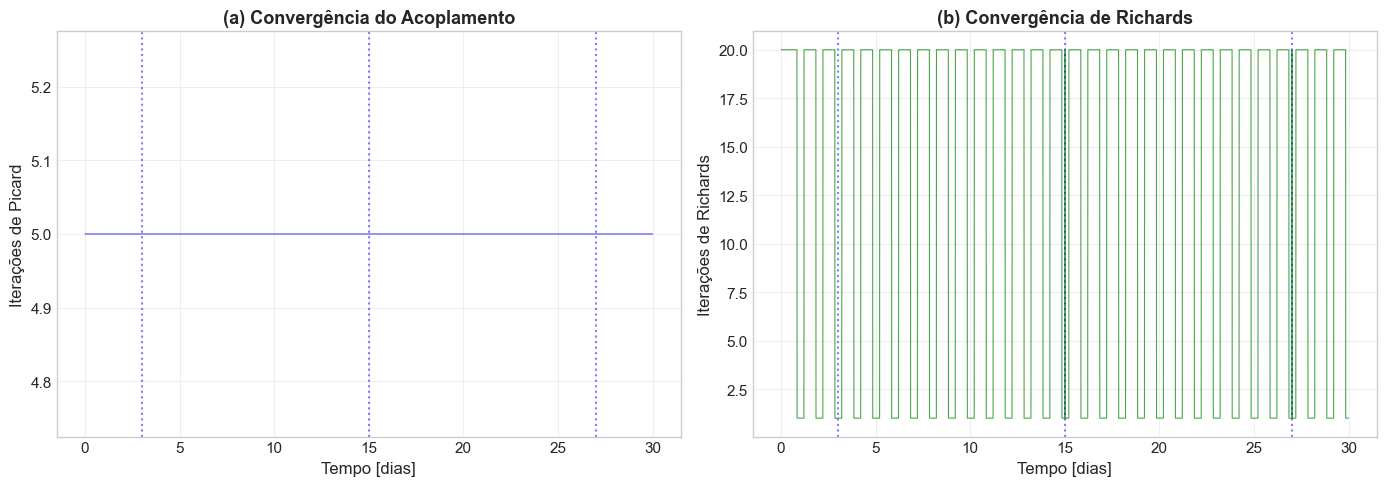


📊 Estatísticas de convergência:
  • Média de iterações de acoplamento: 5.00
  • Máximo de iterações de acoplamento: 5
  • Média de iterações de Richards: 13.15
  • Taxa de convergência de Richards: 36.0%


In [72]:
# ============================================================
# GRÁFICO — Convergência do acoplamento
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Iterações de acoplamento
ax1.plot(t_dias[1:], acopl_iter_hist[1:], 'b-', linewidth=0.8, alpha=0.7)
ax1.set_xlabel('Tempo [dias]', fontsize=12)
ax1.set_ylabel('Iterações de Picard', fontsize=12)
ax1.set_title('(a) Convergência do Acoplamento', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Iterações de Richards
ax2.plot(t_dias[1:], rich_iter_hist[1:], 'g-', linewidth=0.8, alpha=0.7)
ax2.set_xlabel('Tempo [dias]', fontsize=12)
ax2.set_ylabel('Iterações de Richards', fontsize=12)
ax2.set_title('(b) Convergência de Richards', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

for dia_chuva in eventos_chuva:
    ax1.axvline(dia_chuva, color='blue', linestyle=':', alpha=0.5)
    ax2.axvline(dia_chuva, color='blue', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

print(f'\n📊 Estatísticas de convergência:')
print(f'  • Média de iterações de acoplamento: {np.mean(acopl_iter_hist[1:]):.2f}')
print(f'  • Máximo de iterações de acoplamento: {np.max(acopl_iter_hist[1:]):.0f}')
print(f'  • Média de iterações de Richards: {np.mean(rich_iter_hist[1:]):.2f}')
print(f'  • Taxa de convergência de Richards: {100*np.mean(rich_conv_hist[1:]):.1f}%')

> 💡 **Observação:**
> - O acoplamento converge em ~5 iterações (limite máximo) na maioria dos passos.
> - Richards converge em ~1-2 iterações, indicando não-linearidade moderada.
> - Durante eventos de chuva, pode haver aumento nas iterações devido à saturação superficial.

---
## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Aquecimento diurno da superfície:** Durante o dia (6h–18h), a radiação solar aquece a superfície do solo. A temperatura superficial atinge ~35°C ao meio-dia e cai para ~15°C à meia-noite. A radiação de onda longa para o céu (especialmente em céu claro, $\varepsilon_{atm} = 0{,}75$) é o principal mecanismo de resfriamento noturno.

2. **Isolamento térmico com profundidade:** A onda térmica diurna é amortecida exponencialmente com a profundidade. A ~15 cm (profundidade de penetração diurna), a amplitude é ~37% da superficial. A ~50 cm, a oscilação diária é < 0,5°C. O solo funciona como um **isolante térmico natural**.

3. **Temperatura constante em profundidade:** A 3 m, a temperatura permanece constante em ~15°C (média anual). Isso ocorre porque a profundidade de penetração anual (~3,87 m) é maior que o domínio. Este é o princípio da **geotermia rasa**: o solo profundo funciona como reservatório térmico estável.

4. **Efeito da umidade na condutividade:** Com a ET intensificada (10 mm/dia), a umidade varia significativamente entre eventos de chuva. Isso causa variação na condutividade térmica de ~0,35 (seco) a ~1,2 W/(m·K) (úmido). Solo úmido conduz calor ~3× mais eficientemente que solo seco.

5. **Feedback ET-umidade:** Quando a umidade atinge o ponto de murcha ($\theta_{crit}$), a ET é reduzida, evitando secagem excessiva. Este feedback não-linear é capturado pelo modelo de Feddes.

### Limitações do Modelo

- **1D vertical:** Não considera fluxo lateral de água ou calor.
- **Propriedades constantes:** Os parâmetros de van Genuchten são fixos. Na realidade, podem variar com a profundidade (estratificação).
- **Sem histerese:** O modelo não considera histerese na curva de retenção (caminho de secagem vs. molhamento).
- **ET simplificada:** O modelo de Feddes é uma aproximação. Modelos mais realistas incluem resistência estomática e demanda atmosférica.
- **Sem fase de gelo:** Não modela congelamento/descongelamento (relevante para permafrost).
- **Nebulosidade simplificada:** A emissividade atmosférica é binária (claro/nublado).

### Aplicações Práticas

- **Geotermia rasa:** Dimensionamento de trocadores de calor geotérmicos (bombas de calor solo-ar). A temperatura constante a ~3 m é a base do funcionamento das bombas de calor geotérmicas.
- **Agricultura:** Previsão de temperatura do solo para germinação de sementes e planejamento de irrigação. O ponto de murcha é crítico para manejo hídrico.
- **Engenharia civil:** Previsão de degelo do permafrost, dimensionamento de fundações em solos expansivos.
- **Ciências ambientais:** Modelagem de estratificação térmica em lagos e reservatórios.
- **Construção civil:** Projeto de isolamento térmico de edificações enterradas (porões, túneis).

### Conexão com a Teoria

> 📖 **Referência:** A equação de Richards é descrita em Richards (1931) e van Genuchten (1980). O modelo de extração por raízes segue Feddes et al. (1978). O modelo de Côté & Konrad para condutividade térmica é apresentado em Côté & Konrad (2005). A temperatura do céu por Brutsaert (1975) segue a formulação de emissividade atmosférica. O esquema implícito com Picard segue Lugon Jr. et al. (2026), Cap. 8, Seções 8.5–8.7.

---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 8](../notebooks/08_Transferencia_Calor_Solos.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 8.X1

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>